# Polymers 1: chain conformations

Course assignment. Ideal and self-avoiding chains on a lattice, and an off-lattice worm-like chain (WLC) with a stiffness parameter `chi`. The questions are the ones given in the assignment. The chain generators are based on the code given in the course notebook, and `PolymerFun.py` was provided by the course.

Q1: Study the the statistics of the gyration radius for the two types of chain in 2 and 3 dimensions, try to generate >100 conformations for the same polymer length. What is the statistics of the gyration radius for the ideal and for the self-avoiding chain? If the length of the polymer change, how does R-g change?

In [5]:
## import cell ##

import numpy as np
import matplotlib.pyplot as plt
import pylab
from mpl_toolkits.mplot3d import Axes3D ## import to plot polymer conformations in 3D
import random

import importlib
import PolymerFun as pf
importlib.reload(pf)

%matplotlib inline
# %matplotlib qt

plt.close('all') #close all figures if open

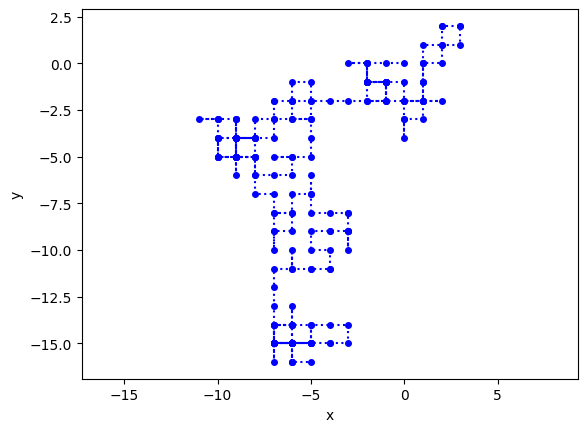

In [6]:
d=2 ## dimensionality of the chain
L=200 ## number of monomers of the chain

id_chain = np.zeros((L, d), dtype=int) ## initialize array for the chain

dice_dim =  np.random.randint(0, d, size=L-1) ## randomly assign the movement dimensionality for each monomer
dice_steps =  2*np.random.randint(0, 2, size=L-1) - 1 ## randomnly assign movement +1 or -1 to each monomer

## create an increment matrix for each monomer (defined on all considered dimensions)
increment_matrix = np.zeros((L-1, d), dtype=int)
increment_matrix[np.arange(L-1), dice_dim] = dice_steps

id_chain[1:] = np.cumsum(increment_matrix, axis=0) ## define the monomer position as the cumulative sum of the increments in the considered dimensions


if d==2:
    fig, ax = plt.subplots()
    ax.plot(id_chain[:,0],id_chain[:,1], ls=':', marker='o', ms=4, color='b')
    ax.set_aspect('equal', adjustable='box')
    ax.axis('equal')
    ax.set_xlabel('x')
    ax.set_ylabel('y')
    
else:
    fig, ax = plt.subplots(subplot_kw={'projection': '3d'})
    ax.plot(id_chain[:,0],id_chain[:,1],id_chain[:,2], ls='--', marker='o', ms=4, color='b')
    pf.set_equal_3d(ax, id_chain)
    ax.set_xlabel('x')
    ax.set_ylabel('y')
    ax.set_zlabel('z')



### define a function to compute the ideal chain

def ID_chain_lattice(L, d):
    id_chain = np.zeros((L, d), dtype=int)
    dice_dim =  np.random.randint(0, d, size=L-1)
    dice_steps =  2*np.random.randint(0, 2, size=L-1) - 1
    increment_matrix = np.zeros((L-1, d), dtype=int)
    increment_matrix[np.arange(L-1), dice_dim] = dice_steps
    id_chain[1:] = np.cumsum(increment_matrix, axis=0)
    return id_chain

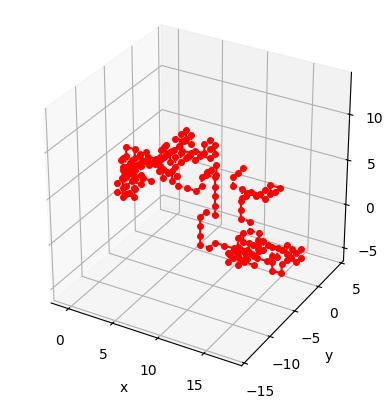

In [7]:
d=3 ## dimensionality of the chain
L=200 ## number of monomers of the chain

while True:
    sa_chain = np.zeros((L, d), dtype=int) ## initialize the array for the self avoiding chain
    visited_positions = {tuple(sa_chain[0])} ## initialize a set for the occupied sites
    
    chain_accepted = True ## define a variable for the state of the chain
    for i in range(1, L): ## loop over the number of monomers
        monomer_accepted = False ## initialize a variable to determine if the position of a monomer is accepted

        for _ in range(50): ## make at most 50 trials to place a monomer, after which the chain is rejected
            dim = np.random.randint(0, d) ## randomly assign the movement dimensionality 
            step = 2*np.random.randint(0, 2) - 1 ## randomnly assign movement +1 or -1

            ## determine the new monomer position as the position of the previous monomer + the movement in the chosen dimension
            new_pos = sa_chain[i-1].copy()
            new_pos[dim] += step

            ## check if the chosen position is not already occupied
            key = tuple(new_pos) 
            if key not in visited_positions: ## if the chosen position is empty
                sa_chain[i] = new_pos ## assign the position 
                visited_positions.add(key) ## add the position to the occupied sites set
                monomer_accepted = True ## accept the position
                break ## exit from the position loop

        if not monomer_accepted: ## if it did no manage to successfully place the monomer
            chain_accepted = False ## reject the chain
            break ## exit from the monomer placing loop
    
    if chain_accepted:
        break

if d==2:
    fig, ax = plt.subplots()
    ax.plot(sa_chain[:,0], sa_chain[:,1], ls=':', marker='o', ms=4, color='r')
    ax.set_aspect('equal', adjustable='box')
    ax.axis('equal')
    ax.set_xlabel('x')
    ax.set_ylabel('y')
    
else: 
    fig, ax = plt.subplots(subplot_kw={'projection': '3d'})
    ax.plot(sa_chain[:,0], sa_chain[:,1], sa_chain[:,2], ls='--', marker='o', ms=4, color='r')
    pf.set_equal_3d(ax, sa_chain)
    ax.set_xlabel('x')
    ax.set_ylabel('y')
    ax.set_zlabel('z')


### define a function to compute the self-avoiding chain

def SA_chain_lattice(L, d):
    while True:
        sa_chain = np.zeros((L, d), dtype=int)
        visited_positions = {tuple(sa_chain[0])}
        chain_accepted = True
        for i in range(1, L):
            monomer_accepted = False
            for _ in range(50):
                dim = np.random.randint(0, d)
                step = 2*np.random.randint(0, 2) - 1
                new_pos = sa_chain[i-1].copy()
                new_pos[dim] += step
                key = tuple(new_pos) 
                if key not in visited_positions:
                    sa_chain[i] = new_pos
                    visited_positions.add(key)
                    monomer_accepted = True
                    break
            if not monomer_accepted:
                chain_accepted = False
                break
        if chain_accepted:
            break
    return sa_chain

In [8]:
def g_radius(chain):
    '''Compute the radius of gyration of a polymer chain given in input as an array of monomer positions
    The function returns the gyration radius and the coordinate array for the center of mass'''
    r_cm = np.mean(chain,0) ## compute the center of mass as the average of monomer position
    rdiff_sum = 0
    L = chain.shape[0]
    ## compute te gyration radius
    for i in range(L):
        rdiff_sum = rdiff_sum + np.sum((chain[i,:]-r_cm)**2)
    r_g = np.sqrt(rdiff_sum/L) 
    return r_g, r_cm

ideal 2d  -> mean=5.28  std=1.45
ideal 3d  -> mean=5.58  std=1.38
SA 2d     -> mean=12.71  std=2.74
SA 3d     -> mean=7.38  std=1.61


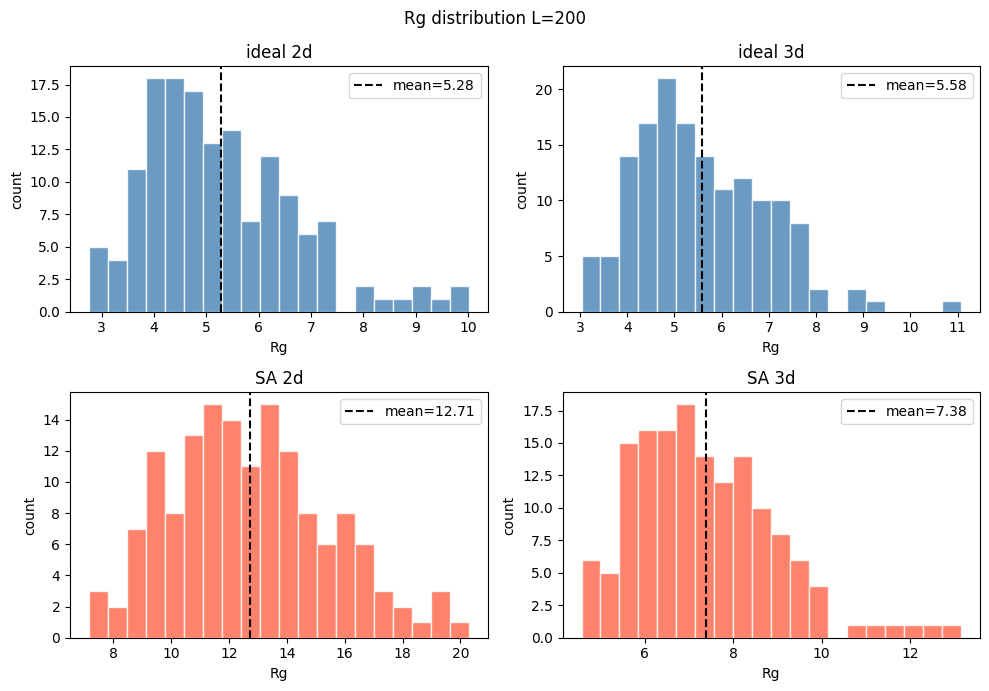

L=20 done
L=50 done
L=100 done
L=200 done
L=400 done


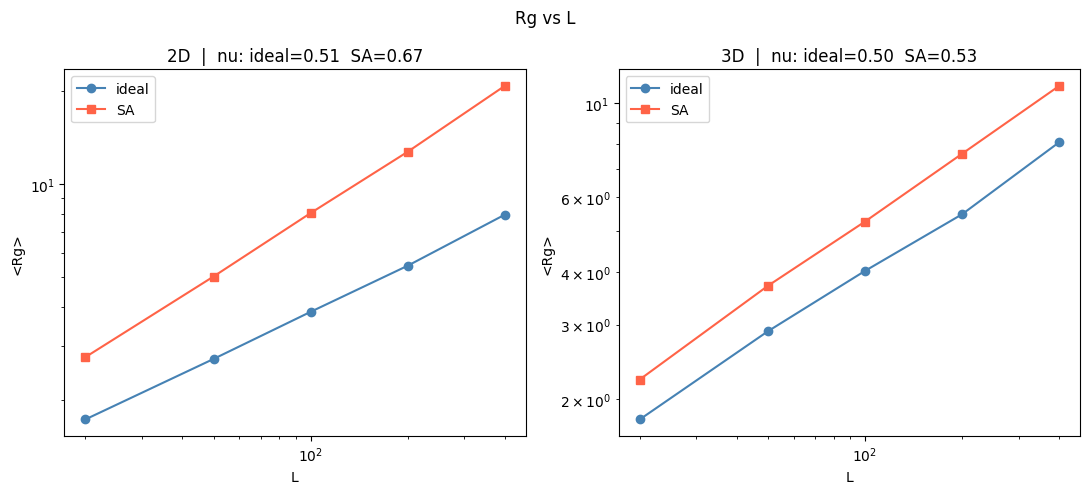

ideal 2d:  nu=0.507  (theory 0.5)
ideal 3d:  nu=0.496  (theory 0.5)
SA 2d:     nu=0.674  (theory 0.75)
SA 3d:     nu=0.531  (theory 0.588)


In [9]:
N = 150
L = 200

Rg_id_2d = []
Rg_id_3d = []
Rg_sa_2d = []
Rg_sa_3d = []

for i in range(N):
    rg, _ = g_radius(ID_chain_lattice(L, 2))
    Rg_id_2d.append(rg)

    rg, _ = g_radius(ID_chain_lattice(L, 3))
    Rg_id_3d.append(rg)

    rg, _ = g_radius(SA_chain_lattice(L, 2))
    Rg_sa_2d.append(rg)

    rg, _ = g_radius(SA_chain_lattice(L, 3))
    Rg_sa_3d.append(rg)

print(f'ideal 2d  -> mean={np.mean(Rg_id_2d):.2f}  std={np.std(Rg_id_2d):.2f}')
print(f'ideal 3d  -> mean={np.mean(Rg_id_3d):.2f}  std={np.std(Rg_id_3d):.2f}')
print(f'SA 2d     -> mean={np.mean(Rg_sa_2d):.2f}  std={np.std(Rg_sa_2d):.2f}')
print(f'SA 3d     -> mean={np.mean(Rg_sa_3d):.2f}  std={np.std(Rg_sa_3d):.2f}')


fig, axes = plt.subplots(2, 2, figsize=(10, 7))
fig.suptitle(f'Rg distribution L={L}')

for ax, data, title, color in zip(axes.flat,
                                   [Rg_id_2d, Rg_id_3d, Rg_sa_2d, Rg_sa_3d],
                                   ['ideal 2d', 'ideal 3d', 'SA 2d', 'SA 3d'],
                                   ['steelblue', 'steelblue', 'tomato', 'tomato']):
    ax.hist(data, bins=20, color=color, edgecolor='white', alpha=0.8)
    ax.axvline(np.mean(data), color='k', linestyle='--', label=f'mean={np.mean(data):.2f}')
    ax.set_title(title)
    ax.set_xlabel('Rg')
    ax.set_ylabel('count')
    ax.legend()

plt.tight_layout()
plt.show()


lengths = [20, 50, 100, 200, 400]
n_per_L = 120

mean_id_2d, mean_id_3d = [], []
mean_sa_2d, mean_sa_3d = [], []

for L in lengths:
    tmp_id2, tmp_id3, tmp_sa2, tmp_sa3 = [], [], [], []
    for _ in range(n_per_L):
        rg, _ = g_radius(ID_chain_lattice(L, 2)); tmp_id2.append(rg)
        rg, _ = g_radius(ID_chain_lattice(L, 3)); tmp_id3.append(rg)
        rg, _ = g_radius(SA_chain_lattice(L, 2)); tmp_sa2.append(rg)
        rg, _ = g_radius(SA_chain_lattice(L, 3)); tmp_sa3.append(rg)
    mean_id_2d.append(np.mean(tmp_id2))
    mean_id_3d.append(np.mean(tmp_id3))
    mean_sa_2d.append(np.mean(tmp_sa2))
    mean_sa_3d.append(np.mean(tmp_sa3))
    print(f'L={L} done')

fig, axes = plt.subplots(1, 2, figsize=(11, 5))
fig.suptitle('Rg vs L')

for ax, id_data, sa_data, dim in zip(axes,
                                      [mean_id_2d, mean_id_3d],
                                      [mean_sa_2d, mean_sa_3d],
                                      [2, 3]):
    ax.loglog(lengths, id_data, 'o-', color='steelblue', label='ideal')
    ax.loglog(lengths, sa_data, 's-', color='tomato', label='SA')
    nu_id = np.polyfit(np.log(lengths), np.log(id_data), 1)[0]
    nu_sa = np.polyfit(np.log(lengths), np.log(sa_data), 1)[0]
    ax.set_title(f'{dim}D  |  nu: ideal={nu_id:.2f}  SA={nu_sa:.2f}')
    ax.set_xlabel('L')
    ax.set_ylabel('<Rg>')
    ax.legend()

plt.tight_layout()
plt.show()

log_L = np.log(lengths)
print(f'ideal 2d:  nu={np.polyfit(log_L, np.log(mean_id_2d), 1)[0]:.3f}  (theory 0.5)')
print(f'ideal 3d:  nu={np.polyfit(log_L, np.log(mean_id_3d), 1)[0]:.3f}  (theory 0.5)')
print(f'SA 2d:     nu={np.polyfit(log_L, np.log(mean_sa_2d), 1)[0]:.3f}  (theory 0.75)')
print(f'SA 3d:     nu={np.polyfit(log_L, np.log(mean_sa_3d), 1)[0]:.3f}  (theory 0.588)')

For question 1 I generated 150 conformations for both ideal and self-avoiding chains in 2D and 3D, computed the gyration radius for each one and plotted the distributions. The self-avoiding chains always came out bigger (for L=200 the mean Rg is 12.7 against 5.3 in 2D, and 7.4 against 5.6 in 3D), which makes sense since they can't fold back on themselves.

Then I checked how Rg scales with the chain length L by running the same thing for different lengths and plotting on a log-log scale — the slope gives the exponent ν. For the ideal chains it matches the theory well (0.51 and 0.50, theory 0.5). For the self-avoiding chains I get 0.67 in 2D and 0.53 in 3D, which is above the ideal value but below the theoretical values of 0.75 and 0.588. I think there are two reasons. The chains are short (20 to 400 monomers) and the scaling law only holds for long chains. Also, the way the chains are grown (one monomer at a time, starting again when the chain gets stuck) does not produce all self-avoiding conformations with the same probability.

Q2: Using the information of the gyration radius for each configuration, how can the intrachain density of the polymer be computed? Can you define a function to compute it? Does the density vary between ideal and self-avoiding chains keeping the length constant? How does the density scale changing polymer length? (hint: generate >100 conformation for each chain type and length to have good sampling statistics)

density test: 0.2260
ideal 2d  -> mean density=2.5585
ideal 3d  -> mean density=0.3966
SA 2d     -> mean density=0.4554
SA 3d     -> mean density=0.1460


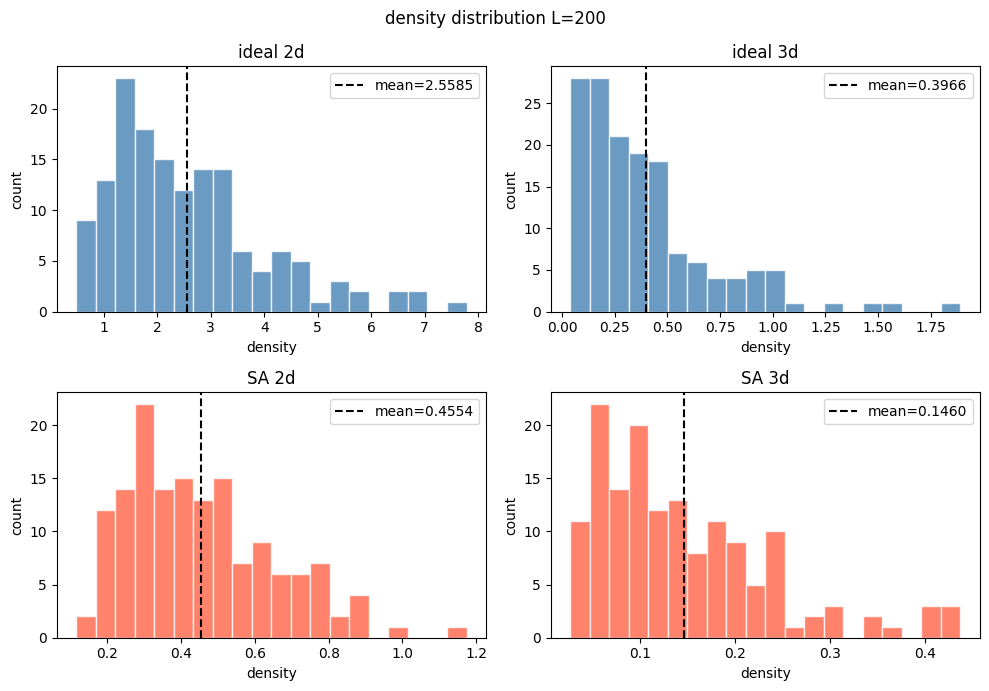

L=20 done
L=50 done
L=100 done
L=200 done
L=400 done


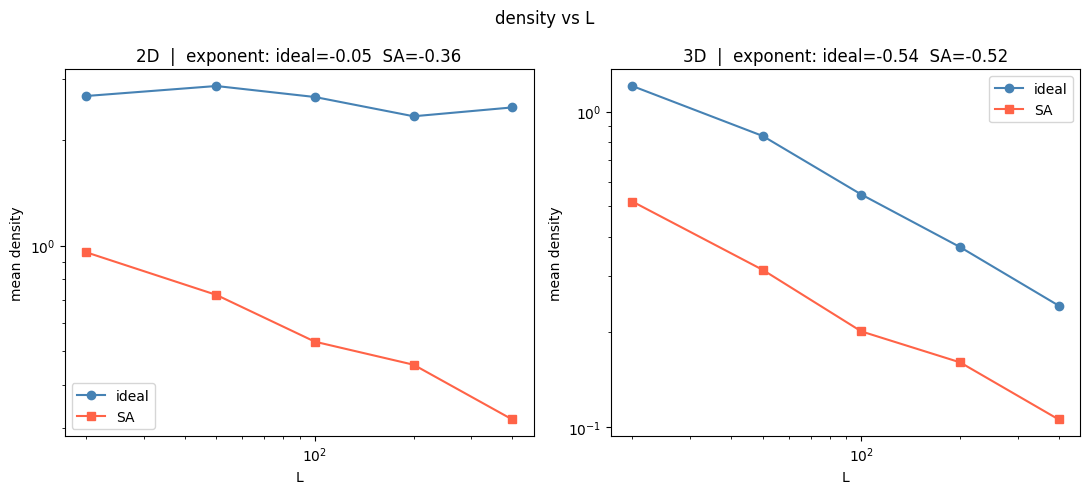

ideal 2d:  exp=-0.046  (theory: 0.00)
ideal 3d:  exp=-0.542  (theory: -0.50)
SA 2d:     exp=-0.360  (theory: -0.50)
SA 3d:     exp=-0.524  (theory: -0.76)


In [10]:
def intrachain_density(chain):
    # compute Rg first
    rg, _ = g_radius(chain)
    L = chain.shape[0]
    d = chain.shape[1]
    

    if d == 2:
        volume = np.pi * rg**2 
    else:
        volume = (4/3) * np.pi * rg**3 
    
    density = L / volume
    return density

chain_test = ID_chain_lattice(200, 3)
print(f'density test: {intrachain_density(chain_test):.4f}')


N = 150
L = 200

dens_id_2d, dens_id_3d = [], []
dens_sa_2d, dens_sa_3d = [], []

for _ in range(N):
    dens_id_2d.append(intrachain_density(ID_chain_lattice(L, 2)))
    dens_id_3d.append(intrachain_density(ID_chain_lattice(L, 3)))
    dens_sa_2d.append(intrachain_density(SA_chain_lattice(L, 2)))
    dens_sa_3d.append(intrachain_density(SA_chain_lattice(L, 3)))

print(f'ideal 2d  -> mean density={np.mean(dens_id_2d):.4f}')
print(f'ideal 3d  -> mean density={np.mean(dens_id_3d):.4f}')
print(f'SA 2d     -> mean density={np.mean(dens_sa_2d):.4f}')
print(f'SA 3d     -> mean density={np.mean(dens_sa_3d):.4f}')


fig, axes = plt.subplots(2, 2, figsize=(10, 7))
fig.suptitle(f'density distribution L={L}')

for ax, data, title, color in zip(axes.flat,
                                   [dens_id_2d, dens_id_3d, dens_sa_2d, dens_sa_3d],
                                   ['ideal 2d', 'ideal 3d', 'SA 2d', 'SA 3d'],
                                   ['steelblue', 'steelblue', 'tomato', 'tomato']):
    ax.hist(data, bins=20, color=color, edgecolor='white', alpha=0.8)
    ax.axvline(np.mean(data), color='k', linestyle='--', label=f'mean={np.mean(data):.4f}')
    ax.set_title(title)
    ax.set_xlabel('density')
    ax.set_ylabel('count')
    ax.legend()

plt.tight_layout()
plt.show()


lengths = [20, 50, 100, 200, 400]
n_per_L = 120

mean_dens_id_2d, mean_dens_id_3d = [], []
mean_dens_sa_2d, mean_dens_sa_3d = [], []

for L in lengths:
    tmp_id2, tmp_id3, tmp_sa2, tmp_sa3 = [], [], [], []
    for _ in range(n_per_L):
        tmp_id2.append(intrachain_density(ID_chain_lattice(L, 2)))
        tmp_id3.append(intrachain_density(ID_chain_lattice(L, 3)))
        tmp_sa2.append(intrachain_density(SA_chain_lattice(L, 2)))
        tmp_sa3.append(intrachain_density(SA_chain_lattice(L, 3)))
    mean_dens_id_2d.append(np.mean(tmp_id2))
    mean_dens_id_3d.append(np.mean(tmp_id3))
    mean_dens_sa_2d.append(np.mean(tmp_sa2))
    mean_dens_sa_3d.append(np.mean(tmp_sa3))
    print(f'L={L} done')

fig, axes = plt.subplots(1, 2, figsize=(11, 5))
fig.suptitle('density vs L')

for ax, id_data, sa_data, dim in zip(axes,
                                      [mean_dens_id_2d, mean_dens_id_3d],
                                      [mean_dens_sa_2d, mean_dens_sa_3d],
                                      [2, 3]):
    ax.loglog(lengths, id_data, 'o-', color='steelblue', label='ideal')
    ax.loglog(lengths, sa_data, 's-', color='tomato', label='SA')
    exp_id = np.polyfit(np.log(lengths), np.log(id_data), 1)[0]
    exp_sa = np.polyfit(np.log(lengths), np.log(sa_data), 1)[0]
    ax.set_title(f'{dim}D  |  exponent: ideal={exp_id:.2f}  SA={exp_sa:.2f}')
    ax.set_xlabel('L')
    ax.set_ylabel('mean density')
    ax.legend()

plt.tight_layout()
plt.show()

log_L = np.log(lengths)
print(f'ideal 2d:  exp={np.polyfit(log_L, np.log(mean_dens_id_2d), 1)[0]:.3f}  (theory: {1-0.5*2:.2f})')
print(f'ideal 3d:  exp={np.polyfit(log_L, np.log(mean_dens_id_3d), 1)[0]:.3f}  (theory: {1-0.5*3:.2f})')
print(f'SA 2d:     exp={np.polyfit(log_L, np.log(mean_dens_sa_2d), 1)[0]:.3f}  (theory: {1-0.75*2:.2f})')
print(f'SA 3d:     exp={np.polyfit(log_L, np.log(mean_dens_sa_3d), 1)[0]:.3f}  (theory: {1-0.588*3:.2f})')

For question 2 I needed to figure out the intrachain density, which is basically how many monomers are packed inside the volume of the chain. The idea is simple — I already have Rg so I can approximate the chain as a sphere in 3D (or a circle in 2D) with that radius, and then density = number of monomers / volume. I wrote a small function for that and tested it on a single chain first to make sure it made sense. Then same as before, I generated 150 conformations for each case and compared the distributions. Ideal chains came out denser than self-avoiding ones (for L=200, 2.56 against 0.46 in 2D and 0.40 against 0.15 in 3D) — which makes sense, since ideal chains can fold back on themselves and get more compact, while self-avoiding ones are forced to spread out.

For the scaling part, since Rg ~ L^ν, the density should go like L^(1-νd) where d is the dimension. The fitted exponents for the ideal chains agree with this (-0.05 against 0 in 2D, -0.54 against -0.50 in 3D). For the self-avoiding chains the density decreases with L, but more slowly than the theory says (-0.36 against -0.50 in 2D, -0.52 against -0.76 in 3D). This is consistent with question 1, where my ν for these chains was already smaller than the theoretical value: with my measured ν the formula gives -0.35 in 2D and -0.59 in 3D. So in 2D the density of the self-avoiding chains falls faster with L than for the ideal chains, as expected, but in 3D my two exponents are almost the same and I cannot see the difference.

Q3: Try to redo the assignements (1) and (2) for the off-lattice chain. re the conformations statistics you extracted from the lattice model different in the off-lattice chain?

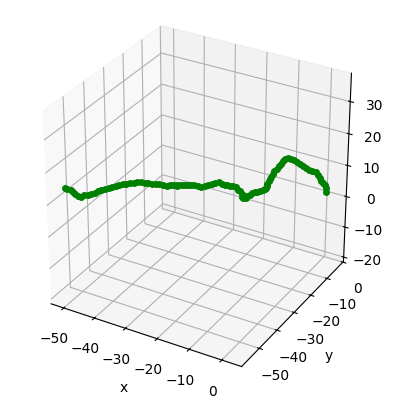

In [12]:
L = 100
d = 3

def WLC_chain_OL(L, d, chi=0.0):
    '''Generate an off-lattice chain of length L on d dimensions.
    chi parameter control the compaction of the chain. chi ∈ [-1,1]
    if chi<0 angles are samples on a biased distribution promoting a compacted conformation.
    if chi>0 angles are samples on a biased distribution promoting an open conformation.'''
    
    while True:
        ol_chain = np.zeros((L, d), dtype=float) ## initialize the array for the self avoiding chain
        visited_positions = {tuple(ol_chain[0])} ## initialize a set for the occupied sites

        chain_accepted = True ## define a variable for the state of the chain
        for i in range(1, L): ## loop over the number of monomers
            monomer_accepted = False ## initialize a variable to determine if the position of a monomer is accepted
            
            for _ in range(50): ## make at most 50 trials to place a monomer, after which the chain is rejected

                if i>1:
                    t, n1, n2 = pf.local_frame(ol_chain, i, d)

                ## 2D chain
                if d==2: 
                    phi = pf.biased_angle_boltzmann(0, 2*np.pi, chi) ## choose a random angle on the plane
                    if i == 1: ## first bond is isotropic
                        step = np.array([np.cos(phi), np.sin(phi)]) ## compute the steps in the considered dimensions keeping the bond lenght constant
                    else: 
                        step = np.cos(phi) * t + np.sin(phi) * n1 ## compute the steps in the considered dimensions keeping the bond lenght constant

                ## 3D chain
                else:
                    phi = np.random.uniform(0, 2*np.pi) ## [0, 2π] azimuth angle on the xy plane normal to previous bond vector
                    psi = pf.biased_angle_boltzmann(0, np.pi, chi) ## [0, π] polar angle between the normal plane and the z axis
                    
                    if i == 1: ## first bond is isotropic
                        ## compute the steps in the considered dimensions keeping the bond lenght constant
                        step = np.array([
                            np.sin(psi) * np.cos(phi),
                            np.sin(psi) * np.sin(phi),
                            np.cos(psi)])
                    else:
                        ## compute the steps in the considered dimensions keeping the bond lenght constant
                        step = (
                            np.cos(psi) * t +
                            np.sin(psi) * np.cos(phi) * n1 +
                            np.sin(psi) * np.sin(phi) * n2)


                ## determine the new monomer position as the position of the previous monomer + the movement in the chosen dimension
                new_pos = ol_chain[i-1] + step    
                ## check if the chosen position is not already occupied
                key = tuple(np.round(new_pos, 10))
                if key not in visited_positions: ## if the chosen position is empty
                    ol_chain[i] = new_pos ## assign the position 
                    visited_positions.add(key) ## add the position to the occupied sites set
                    monomer_accepted = True ## accept the position
                    break ## exit from the position loop
    
            if not monomer_accepted: ## if it did no manage to successfully place the monomer
                chain_accepted = False ## reject the chain
                break ## exit from the monomer placing loop
        if chain_accepted: 
                break ## if the chain is accepted exit the while loop
    return ol_chain

ol_chain = WLC_chain_OL(L, d, chi=0.7)

if d==2:
    fig, ax = plt.subplots()
    ax.plot(ol_chain[:,0], ol_chain[:,1], ls=':', marker='o', ms=4, color='g')
    ax.set_aspect('equal', adjustable='box')
    ax.axis('equal')
    ax.set_xlabel('x')
    ax.set_ylabel('y')
    
else: 
    fig, ax = plt.subplots(subplot_kw={'projection': '3d'})
    ax.plot(ol_chain[:,0], ol_chain[:,1], ol_chain[:,2], ls='--', marker='o', ms=4, color='g')
    pf.set_equal_3d(ax, ol_chain)
    ax.set_xlabel('x')
    ax.set_ylabel('y')
    ax.set_zlabel('z')

WLC 2d  -> mean Rg=21.49  std=5.96
WLC 3d  -> mean Rg=22.19  std=4.72
WLC 2d  -> mean density=0.1708
WLC 3d  -> mean density=0.0058


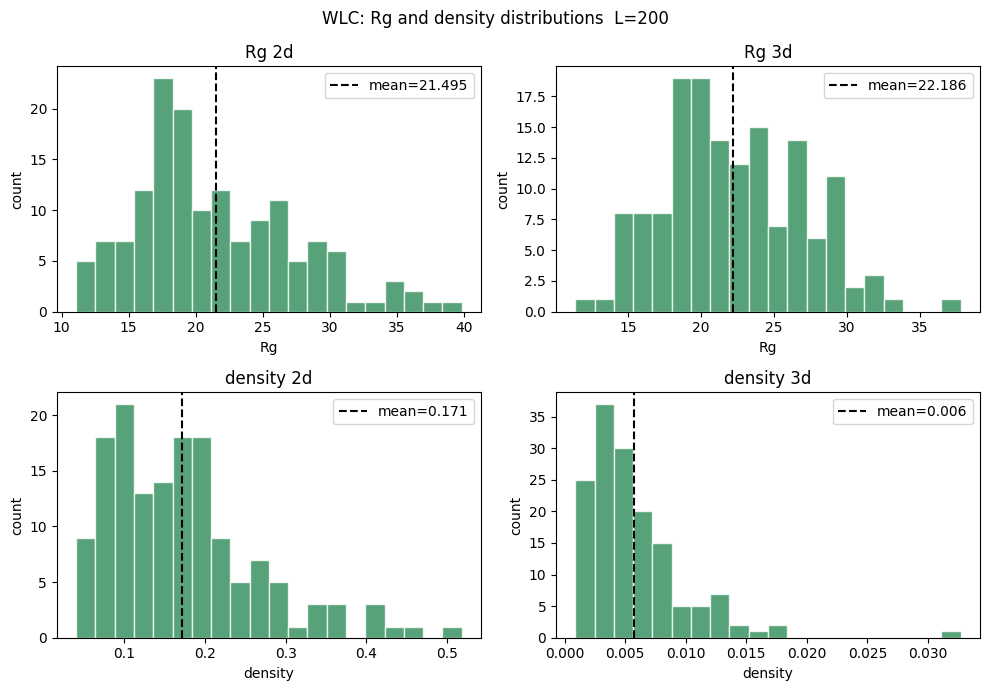

L=20 done
L=50 done
L=100 done
L=200 done
L=400 done


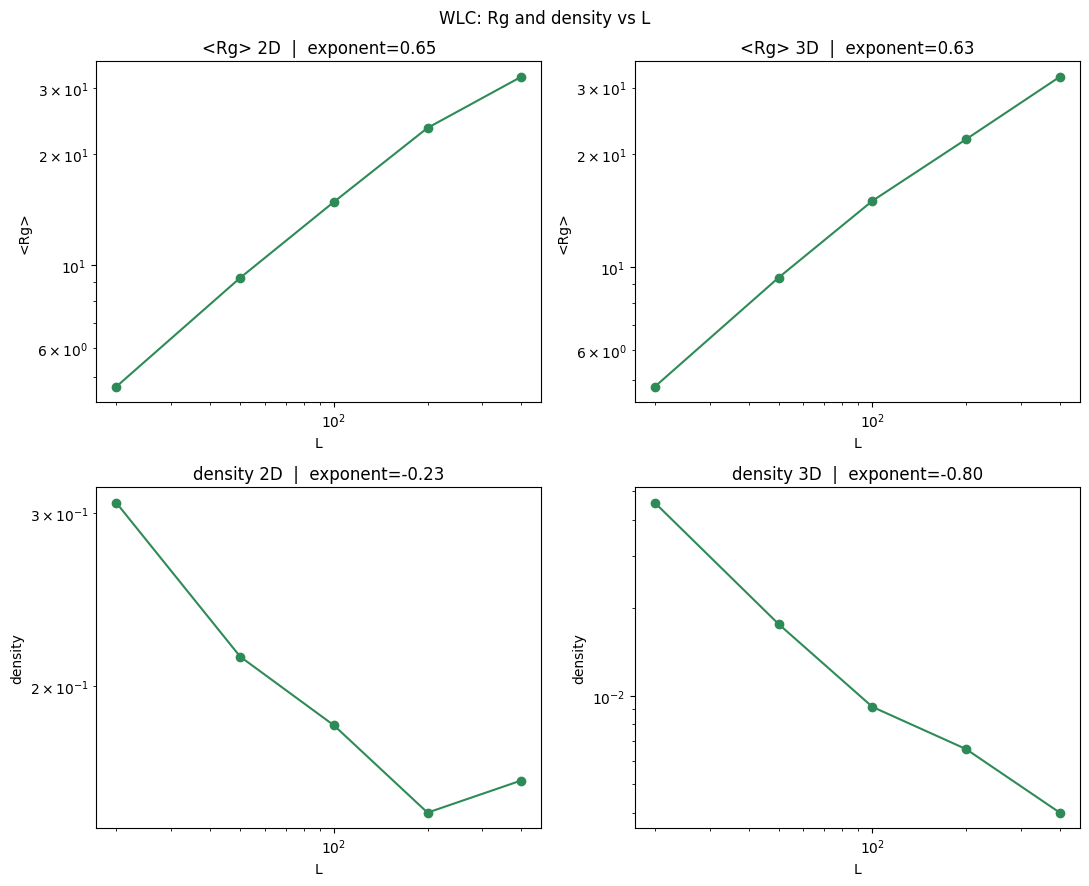

WLC Rg scaling:  2d nu=0.649   3d nu=0.632
(compare: ideal=0.5, SA 2d=0.75, SA 3d=0.588)

WLC density scaling:
  2d: -0.230  (theory: -0.30)
  3d: -0.800  (theory: -0.90)


In [13]:
N = 150
L = 200

Rg_wlc_2d = []
Rg_wlc_3d = []
dens_wlc_2d = []
dens_wlc_3d = []

for _ in range(N):
    chain = WLC_chain_OL(L, 2)
    rg, _ = g_radius(chain)
    Rg_wlc_2d.append(rg)
    dens_wlc_2d.append(intrachain_density(chain))

    chain = WLC_chain_OL(L, 3)
    rg, _ = g_radius(chain)
    Rg_wlc_3d.append(rg)
    dens_wlc_3d.append(intrachain_density(chain))

print(f'WLC 2d  -> mean Rg={np.mean(Rg_wlc_2d):.2f}  std={np.std(Rg_wlc_2d):.2f}')
print(f'WLC 3d  -> mean Rg={np.mean(Rg_wlc_3d):.2f}  std={np.std(Rg_wlc_3d):.2f}')
print(f'WLC 2d  -> mean density={np.mean(dens_wlc_2d):.4f}')
print(f'WLC 3d  -> mean density={np.mean(dens_wlc_3d):.4f}')

fig, axes = plt.subplots(2, 2, figsize=(10, 7))
fig.suptitle(f'WLC: Rg and density distributions  L={L}')

for ax, data, title in zip(axes.flat,
                            [Rg_wlc_2d, Rg_wlc_3d, dens_wlc_2d, dens_wlc_3d],
                            ['Rg 2d', 'Rg 3d', 'density 2d', 'density 3d']):
    ax.hist(data, bins=20, color='seagreen', edgecolor='white', alpha=0.8)
    ax.axvline(np.mean(data), color='k', linestyle='--', label=f'mean={np.mean(data):.3f}')
    ax.set_title(title)
    ax.set_xlabel(title.split()[0])
    ax.set_ylabel('count')
    ax.legend()

plt.tight_layout()
plt.show()

lengths = [20, 50, 100, 200, 400]
n_per_L = 120

mean_Rg_wlc_2d, mean_Rg_wlc_3d = [], []
mean_dens_wlc_2d, mean_dens_wlc_3d = [], []

for L in lengths:
    tmp_rg2, tmp_rg3, tmp_d2, tmp_d3 = [], [], [], []
    for _ in range(n_per_L):
        chain = WLC_chain_OL(L, 2)
        rg, _ = g_radius(chain)
        tmp_rg2.append(rg)
        tmp_d2.append(intrachain_density(chain))

        chain = WLC_chain_OL(L, 3)
        rg, _ = g_radius(chain)
        tmp_rg3.append(rg)
        tmp_d3.append(intrachain_density(chain))

    mean_Rg_wlc_2d.append(np.mean(tmp_rg2))
    mean_Rg_wlc_3d.append(np.mean(tmp_rg3))
    mean_dens_wlc_2d.append(np.mean(tmp_d2))
    mean_dens_wlc_3d.append(np.mean(tmp_d3))
    print(f'L={L} done')

fig, axes = plt.subplots(2, 2, figsize=(11, 9))
fig.suptitle('WLC: Rg and density vs L')

for ax, data_2d, data_3d, ylabel in zip(axes.flat,
                                         [mean_Rg_wlc_2d, mean_dens_wlc_2d],
                                         [mean_Rg_wlc_3d, mean_dens_wlc_3d],
                                         ['<Rg>', 'density']):
    break  

log_L = np.log(lengths)

for ax, data, dim, ylabel in zip(
        [axes[0,0], axes[0,1], axes[1,0], axes[1,1]],
        [mean_Rg_wlc_2d, mean_Rg_wlc_3d, mean_dens_wlc_2d, mean_dens_wlc_3d],
        [2, 3, 2, 3],
        ['<Rg>', '<Rg>', 'density', 'density']):
    ax.loglog(lengths, data, 'o-', color='seagreen')
    exp = np.polyfit(log_L, np.log(data), 1)[0]
    ax.set_title(f'{ylabel} {dim}D  |  exponent={exp:.2f}')
    ax.set_xlabel('L')
    ax.set_ylabel(ylabel)

plt.tight_layout()
plt.show()

nu_wlc_2d = np.polyfit(log_L, np.log(mean_Rg_wlc_2d), 1)[0]
nu_wlc_3d = np.polyfit(log_L, np.log(mean_Rg_wlc_3d), 1)[0]
print(f'WLC Rg scaling:  2d nu={nu_wlc_2d:.3f}   3d nu={nu_wlc_3d:.3f}')
print(f'(compare: ideal=0.5, SA 2d=0.75, SA 3d=0.588)')
print()
print(f'WLC density scaling:')
print(f'  2d: {np.polyfit(log_L, np.log(mean_dens_wlc_2d), 1)[0]:.3f}  (theory: {1-nu_wlc_2d*2:.2f})')
print(f'  3d: {np.polyfit(log_L, np.log(mean_dens_wlc_3d), 1)[0]:.3f}  (theory: {1-nu_wlc_3d*3:.2f})')

For this question I redid questions 1 and 2 but using the off-lattice worm-like chain instead of the lattice chains. The structure is exactly the same: generate 150 conformations, compute Rg and density for each one, plot the distributions, then check the scaling with L on a log-log plot.

With chi=0 the chains are much larger than the lattice chains of the same length: for L=200 the mean Rg is about 22, against about 5.5 for the ideal lattice chain and 7–13 for the self-avoiding one, and the density is much lower. The scaling exponent is also different: I get ν = 0.65 in 2D and 0.63 in 3D, clearly above the ideal value of 0.5.

At first I expected the chain with chi=0 to behave like a freely jointed chain, but that is not the case: chi=0 still gives a stiff chain. In question 5 I find a persistence length of about 9 bonds for chi=0, so chains of 20 to 400 monomers are only about 2 to 45 persistence lengths long. Chains this short are partly rod-like (a rod has ν=1) and only very long chains behave like a coil (ν=0.5), so an exponent between the two is reasonable. The freely jointed case is chi=-1 (see question 4).

The density exponents (-0.23 and -0.80) are close to what I get from 1-νd with my measured ν (-0.30 and -0.90). So the statistics are different from the lattice model, and I think the main reason is the stiffness of the chain and not the fact that it is off-lattice.

Q4: The function WLC_chain_OL takes as input a "chi" parameter, explained in better details below. How does the chain conformation change by changing this parameter? Can you give a physical interpetation (hint: base you answer on the chain configuration parameters by using the g_radius function to retrieve the chain gyration radius and the angle_bonds function from the PolymerFun.py file to get the bond-bond angles for the polymer chain).

chi=-1 done  |  mean Rg 2d=5.49  3d=5.33
chi=-0.5 done  |  mean Rg 2d=14.41  3d=15.13
chi=0 done  |  mean Rg 2d=21.83  3d=22.84
chi=0.5 done  |  mean Rg 2d=27.38  3d=26.17
chi=0.9 done  |  mean Rg 2d=30.89  3d=29.90


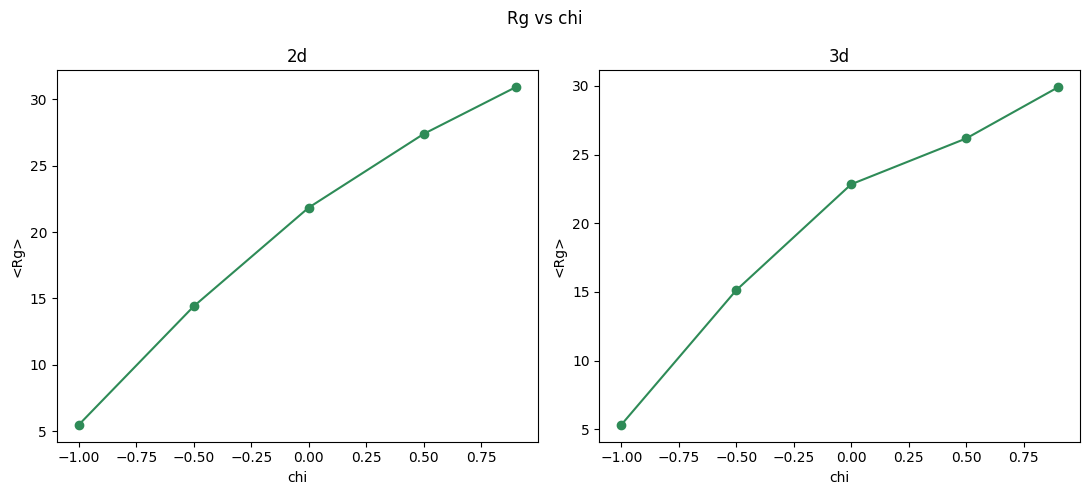

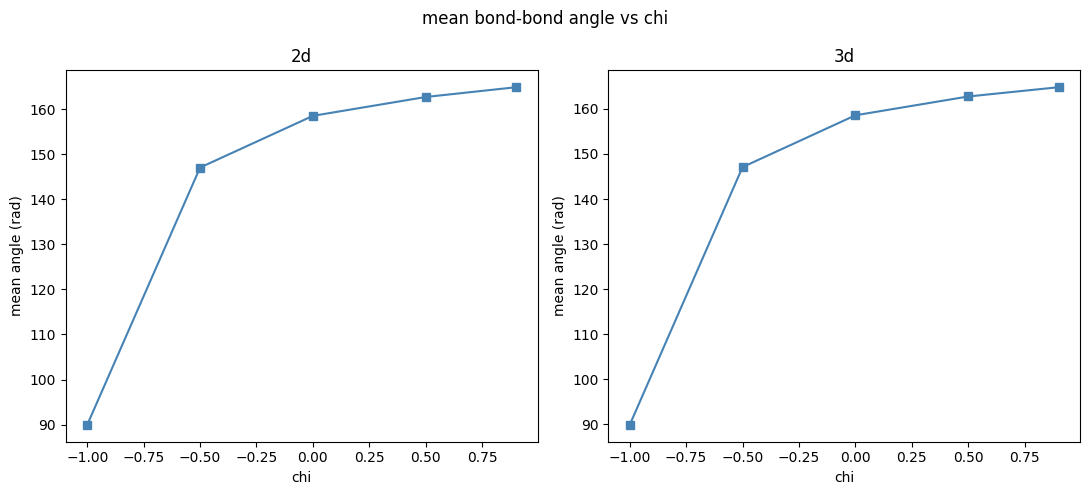

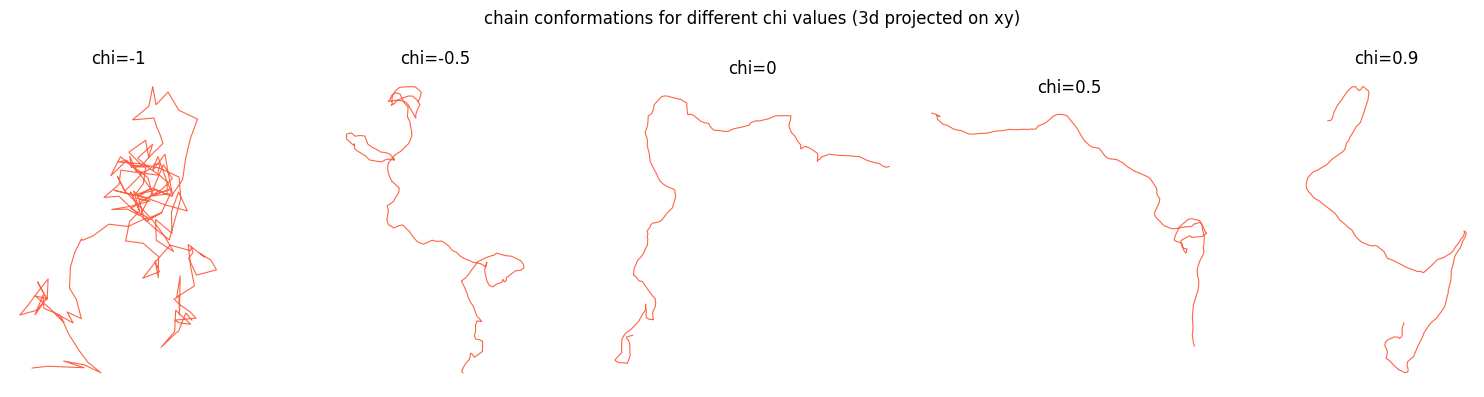

In [14]:
N = 100
L = 200
chi_values = [-1, -0.5, 0, 0.5, 0.9]  
mean_Rg = {'2d': [], '3d': []}
mean_angles = {'2d': [], '3d': []}

for chi in chi_values:
    rg_2d, rg_3d = [], []
    ang_2d, ang_3d = [], []

    for _ in range(N):
        chain = WLC_chain_OL(L, 2, chi=chi)
        rg, _ = g_radius(chain)
        rg_2d.append(rg)
        ang_2d.append(np.mean(pf.angle_bonds(chain)))  

        chain = WLC_chain_OL(L, 3, chi=chi)
        rg, _ = g_radius(chain)
        rg_3d.append(rg)
        ang_3d.append(np.mean(pf.angle_bonds(chain)))

    mean_Rg['2d'].append(np.mean(rg_2d))
    mean_Rg['3d'].append(np.mean(rg_3d))
    mean_angles['2d'].append(np.mean(ang_2d))
    mean_angles['3d'].append(np.mean(ang_3d))
    print(f'chi={chi} done  |  mean Rg 2d={np.mean(rg_2d):.2f}  3d={np.mean(rg_3d):.2f}')


fig, axes = plt.subplots(1, 2, figsize=(11, 5))
fig.suptitle('Rg vs chi')

for ax, dim in zip(axes, ['2d', '3d']):
    ax.plot(chi_values, mean_Rg[dim], 'o-', color='seagreen')
    ax.set_xlabel('chi')
    ax.set_ylabel('<Rg>')
    ax.set_title(dim)

plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(11, 5))
fig.suptitle('mean bond-bond angle vs chi')

for ax, dim in zip(axes, ['2d', '3d']):
    ax.plot(chi_values, mean_angles[dim], 's-', color='steelblue')
    ax.set_xlabel('chi')
    ax.set_ylabel('mean angle (rad)')
    ax.set_title(dim)

plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, len(chi_values), figsize=(16, 4))
fig.suptitle('chain conformations for different chi values (3d projected on xy)')

for ax, chi in zip(axes, chi_values):
    chain = WLC_chain_OL(L, 3, chi=chi)
    ax.plot(chain[:,0], chain[:,1], '-', lw=0.8, color='tomato')
    ax.set_title(f'chi={chi}')
    ax.set_aspect('equal')
    ax.axis('off')

plt.tight_layout()
plt.show()

I tested different values of chi from -1 to 0.9 and looked at how Rg and the bond-bond angles change. As chi gets closer to 1 the chain gets stiffer: the mean Rg grows from about 5.4 at chi=-1 to about 30 at chi=0.9, and the mean angle between consecutive bonds goes from 90° to about 165° (180° would be a straight chain; the axis label of the plot says rad but the values are in degrees). At chi=-1 there is no preferred direction, the chain is a random coil and its Rg is the same as for the ideal lattice chain of question 1. Physically, chi sets the bending stiffness: with a high chi it is unlikely for a bond to point away from the direction of the previous one. I also plotted one chain per chi value and you can see it go from a tangled coil to a much more stretched out shape.

Q5: Look at the persistence_length function found in the PolymerFun.py file: How can this function be used? Try to give a physical explanation of the output of the function. How can you change the persistence length of the polymer? Why? How does it depends on the "chi" parameter? (hint: for best results in studying the persistence length use polymer of length L>5000)

persistence length for chi=0.5: 12.757368818252335
chi=-0.9 done  |  pl 2d=0.67  pl 3d=0.72
chi=-0.5 done  |  pl 2d=3.91  pl 3d=3.72
chi=0 done  |  pl 2d=9.11  pl 3d=8.84
chi=0.5 done  |  pl 2d=13.58  pl 3d=13.85
chi=0.7 done  |  pl 2d=15.94  pl 3d=16.24
chi=0.9 done  |  pl 2d=18.16  pl 3d=17.93


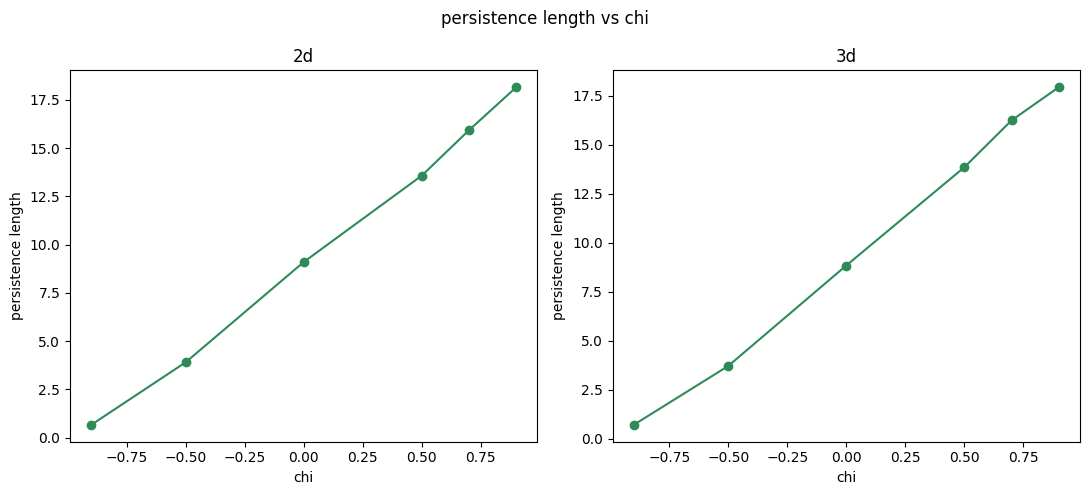

In [21]:
L = 5000
chain = WLC_chain_OL(L, 3, chi=0.5)
pl = pf.persistence_length(chain)
print(f'persistence length for chi=0.5: {pl[0]}')


chi_values = [-0.9, -0.5, 0, 0.5, 0.7, 0.9]
N = 10  

mean_pl_2d = []
mean_pl_3d = []

for chi in chi_values:
    tmp_2d, tmp_3d = [], []
    for _ in range(N):
        chain = WLC_chain_OL(L, 2, chi=chi)
        tmp_2d.append(pf.persistence_length(chain)[0])  

        chain = WLC_chain_OL(L, 3, chi=chi)
        tmp_3d.append(pf.persistence_length(chain)[0])

    mean_pl_2d.append(np.mean(tmp_2d))
    mean_pl_3d.append(np.mean(tmp_3d))
    print(f'chi={chi} done  |  pl 2d={np.mean(tmp_2d):.2f}  pl 3d={np.mean(tmp_3d):.2f}')

fig, axes = plt.subplots(1, 2, figsize=(11, 5))
fig.suptitle('persistence length vs chi')

for ax, pl_data, dim in zip(axes, [mean_pl_2d, mean_pl_3d], ['2d', '3d']):
    ax.plot(chi_values, pl_data, 'o-', color='seagreen')
    ax.set_xlabel('chi')
    ax.set_ylabel('persistence length')
    ax.set_title(dim)

plt.tight_layout()
plt.show()

I used pf.persistence_length to compute the persistence length of the chain for different chi values. The function computes how the correlation between the directions of two bonds decays with their distance along the chain and fits an exponential to it. It returns a tuple, and the first element is the persistence length.

Physically the persistence length tells you over what distance the chain "remembers" its direction — basically how stiff it is. A short persistence length means the chain bends a lot and quickly loses track of where it was pointing, while a long persistence length means it stays straight for longer.

The persistence length can be changed with chi. As chi increases toward 1 the persistence length grows, from about 0.7 bonds at chi=-0.9 to about 18 bonds at chi=0.9, and the values in 2D and 3D are the same. This makes sense because a higher chi means a stiffer chain. At chi close to -1 the persistence length is very short since the chain bends randomly with no memory of the previous bond direction.